# Chapter 6 | Case Study B1 | **Testing the Likelihood of Loss on a Stock Portfolio** #

In this notebook, I'll reproduce the authors' case study on a **one-sided hypothesis test of a probability**. It builds on the Chapter 5 case study (*What likelihood of loss to expect on a stock portfolio?*) and uses the <code>sp500</code> dataset: daily values of the S&P 500 index, 2006–2016.

**Main question**: can we tolerate the risk of large losses? We accept daily losses of 5% or more as long as they happen on **less than 1% of the days**.
**Chosen statistic**: TODO: *define it here (hint: the share of days with a 5%+ loss, compared to the 1% threshold).*

## 1. Read the data ##

In [14]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
from scipy import stats
from mizani.formatters import percent_format
from plotnine import *

warnings.filterwarnings("ignore")

In [15]:
from bkda.paths import DATA_DIR, ROOT_DIR

HERE = f"{ROOT_DIR}chapters/ch06-testing_hypotheses/case_studies/stock_market_loss_test/"
data_in = f"{DATA_DIR}sp500/clean/"
data_out = f"{HERE}data/clean/"
output = f"{HERE}output/"

In [16]:
from bkda.helpers import *

In [17]:
sp500 = pd.read_csv(data_in + "SP500_2006_16_data.csv", parse_dates=["DATE"])
sp500 = sp500.dropna().reset_index(drop=True)
sp500.shape

(2519, 2)

The file has 2611 rows, 92 of which have no value. Those are market holidays, stored as `#N/A`. `parse_dates=["DATE"]` turns date into real dates, getting us 2519 trading days.

## 2. Prepare the data ##
> TODO: Steps to cover:
> - Compute the **daily % return** from the index value.
> - Create the binary variable **`loss5`**: 1 if the daily return is below −5%, 0 otherwise.
> - Check: how many days do you have (*n*), and how many are loss days? Watch the first day, which has no return.

In [18]:
# Daily % return
sp500["pct_return"] = sp500["VALUE"].pct_change() * 100
sp500.head(10)

,DATE,VALUE,pct_return
0,2006-08-25,1295.09,NaN
1,2006-08-28,1301.78,0.516566
2,2006-08-29,1304.28,0.192045
3,2006-08-30,1304.27,-0.000767
4,2006-08-31,1303.82,-0.034502
5,2006-09-01,1311.01,0.551456
6,2006-09-05,1313.25,0.170861
7,2006-09-06,1300.26,-0.989149
8,2006-09-07,1294.02,-0.479904
9,2006-09-08,1298.92,0.378665


In [19]:
# Drop NaN
sp500 = sp500.dropna().reset_index(drop=True)
sp500.head()

,DATE,VALUE,pct_return
0,2006-08-28,1301.78,0.516566
1,2006-08-29,1304.28,0.192045
2,2006-08-30,1304.27,-0.000767
3,2006-08-31,1303.82,-0.034502
4,2006-09-01,1311.01,0.551456


In [29]:
# Binary indicator loss5. Gives you a TRUE/FALSE, converting it into 1/0 with astype. Converted loss5 to an ordinary variable that we can average.
sp500["loss5"] = (sp500["pct_return"] < -5).astype(int)
sp500.loc[sp500["loss5"] == 1]

,DATE,VALUE,pct_return,loss5
525,2008-09-29,1106.39,-8.789705,1
531,2008-10-07,996.23,-5.739481,1
533,2008-10-09,909.92,-7.616708,1
537,2008-10-15,907.84,-9.034980,1
542,2008-10-22,896.78,-6.101251,1
552,2008-11-05,952.77,-5.267711,1
553,2008-11-06,904.88,-5.026397,1
557,2008-11-12,852.30,-5.189388,1
562,2008-11-19,806.58,-6.115560,1
563,2008-11-20,752.44,-6.712291,1


In [31]:
# Sanity checks: n, number of loss days
n = len(sp500)
n_losses = sp500["loss5"].sum()
print(f"Days: {n}, loss days: {n_losses}, worst day: {sp500['pct_return'].min():.2f}%")

Days: 2518, loss days: 13, worst day: -9.03%


Observation: the book says 2519 observations, but technically we have 2518,as the former represents the number of index values, and returns are always one fewer.

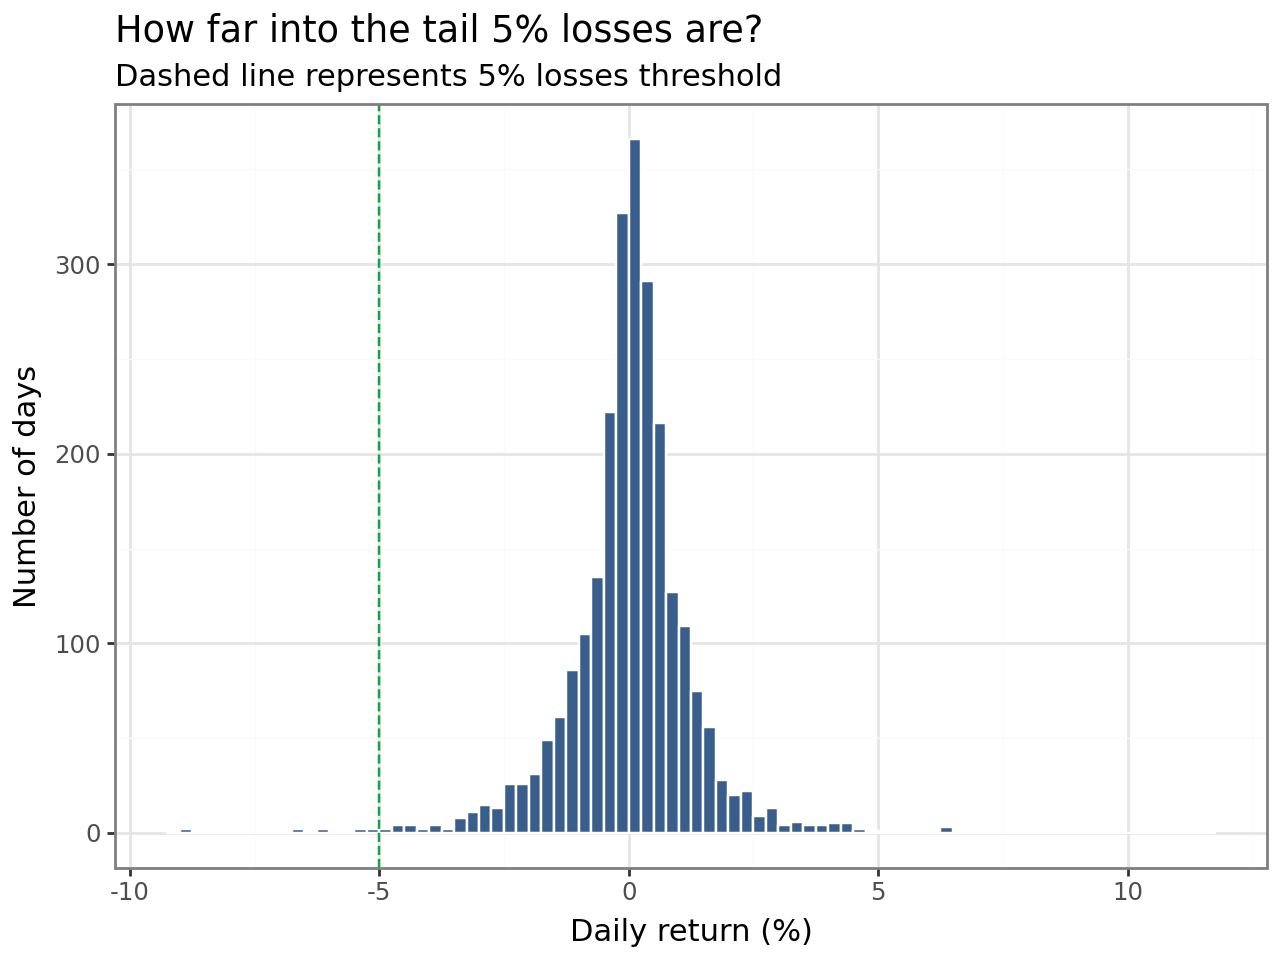

In [33]:
(
    ggplot(sp500, aes("pct_return"))
    + geom_histogram(binwidth=0.25, boundary=0, fill=color[0], color="white", alpha=0.8)
    + geom_vline(xintercept=-5, linetype="dashed", color=color[1])
    + labs(x="Daily return (%)", y="Number of days")
    + theme_bw()
    + labs(title = "How far into the tail 5% losses are?", subtitle="Dashed line represents 5% losses threshold")
)

## 3. Define the statistic ##
> TODO: Explain why **the mean of a 0/1 variable is a probability (relative frequency)**, and why that lets us reuse everything we know about averages (SE, t-test, CI).
>
> Write the statistic in LaTeX, e.g. $\hat{s} = \overline{\text{loss5}} - 0.01$, and compute its value in the data.

In [34]:
# Share of loss days and the statistic s_hat
p_hat = sp500["loss5"].mean()
s_hat = p_hat - 0.01
print(f"Share of loss days: {p_hat:4f} ({p_hat:.2%})")
print(f"s_hat = {s_hat:.4f}")

Share of loss days: 0.005163 (0.52%)
s_hat = -0.0048



The mean of a 0/1 variable is (number of 1s) / n, which is exactly the share of loss days. Hence, a probability *is* an average. That means we learned about the sampling the destibution applies directly: the CLT, the SE, the t-test, and the CI. We subtract 0.01 so that "is the share below 1%" becomes "is s below 0?". Tests are easiest to read when the threshold is at zero.

$$\hat{s} = \overline{\text{loss5}}  - 0.01$$

## 4. Hypotheses ##

### $H_0$ and $H_A$
$$H_0: s_{\text{true}} \geq 0 \qquad H_A: s_{\text{true}} < 0$$
Here, we want to translate our question into a null and an appropriate alternative hypothesis, making sure that the proportion of large losses is **less than 1%**. So, we can see that this part goes into $H_A$, while the null cover all other all other possibilities (hence the greater or equal sign).

### False positive (rejecting a true $H_0$)
A false positive (type-I) happens when we reject $H_0$ when it is true. It is false because it represents an error and positive because we actively take the decision to reject the protected null. In our case, we would take the decision that the number of days with unacceptable loss rates is below the 1% rate. We would be advising an investor to take a risky move that would be erroneuous. This could represent a costly error.

### False negative (not rejecting a false $H_0$)
Here, our error (type-I) is related to our passiveness towards our hypothesis. $H_0$ would be false but we would still not reject it.  In our scenario, we would avise the investor not to take any risks as the null hypothesis of having days with large losses equal or above 1% to be true. This is a more conservative move, but it could lead to opportunity costs to the investor, as they could exit a good investment when the risk was acceptable.

### Which is more costly?
That could largely depend on the amount invested and the risk the investor is willing to take. A false positive is definitely more risky and could lead to severe real losses. A false negative is more about what could have happened and how this scenario would not materialize as we'd have advised the investor not to take any action when they could have profitted from it.

### Fix the **significance level** before testing
The probability of a false positive is called the **size of the test**. The maximum probability we tolerate is the **level of significance**. When we fix this level at 5%, for example, and end up rejecting $H_0$, we say that the statistic we tested is "*significant at 5%*". The probability of avoiding a false negative is the **power of the test**. As a result, we usually can fix the level of significance at **5%** and hope for a high power - that is, a high probabiluty of avoiding a false negative. As our false positive case could lead to severe losses, we could raise the power of the test by setting it at 1%.

## 5. Carry out the test ##
### 5.1 Is the statistic in the region of the null? ###


In [35]:
s_hat < 0

np.True_

We can see that our statistic - the average mean of `loss5` - is equivalent to our $H_A$ being true. If it were false, we'd stop, as a positve $\hat{s}$ would fall within the null region.

### 5.2 Standard error and t-statistic (by hand) ###
> TODO: For a proportion, $SE = \sqrt{\hat{p}(1-\hat{p})/n}$. Compare it with `std / sqrt(n)` of `loss5`: are they the same? Why (almost)?

In [42]:
# SE two ways
se_formula = np.sqrt(p_hat * (1 - p_hat) / n)
se_sd = sp500["loss5"].std() / np.sqrt(n)
print(f"SE (proportion formula):    {se_formula:.6f}")
print(f"SE (std / sqrt(n)):         {se_sd:.6f}")

SE (proportion formula):    0.001428
SE (std / sqrt(n)):         0.001428


They are almost identical, mathcing to about 6 decimals. For a 0/1 variable, the variance is exactly p(1 - p), so the formulas are the same idea. The tiny gap is because `.std()` divides by `n - 1`, while the proportion formula divides by n. This difference is hence negligible.

In [44]:
# t-statistic
t_stat = s_hat / se_sd
t_stat


np.float64(-3.3862058433914672)

The general formula is t = (estimate - value under $H_0$ / SE). As the value under $H_0$ is already folded into $\hat{s}$ we don't need to consider it again in the formula.

### 5.3 p-value with SciPy ###
> TODO: Get the **two-sided** p-value, then the **one-sided** one by halving it. Then confirm with SciPy's `alternative=` argument.
>
> Compare your p-value with the book's (p. 159). Do they match? If not, why doesn't the conclusion change?

In [46]:
# Two-sided test, then one-sided p-value
t_two, p_two = stats.ttest_1samp(sp500["loss5"], popmean=0.01)
p_one = p_two / 2
print(f"t = {t_two:.4f}, two_sided p = {p_two:.5f}, one-sided p= {p_one:.5f}")

t = -3.3862, two_sided p = 0.00072, one-sided p= 0.00036


In [48]:
# Same test using the alternative= argument
stats.ttest_1samp(sp500["loss5"], popmean=0.01, alternative="less")

TtestResult(statistic=np.float64(-3.3862058433914672), pvalue=np.float64(0.00035977060996994844), df=np.int64(2517))

`less` means $H_A$ is below `popmean`. It returns p = 0.000359 directly, which matched our halved value (rounded). Note that this is the safer habit in practice, as halving by hand is only valid once you've dune the null-region from our earlier steps in 5.1.

### Comparing with the book results
The book describes the two-sided p-value as 0.0000, while our results yield `0.0007`. While the conclusion does not change, as the values are far below 0.05, it is worth noticing this difference when studying. Data can change also, leading to different outputs.

### 5.4 Alternative tests for a proportion - the exact binomial test and the z-test
The test from section 5 relies on the Central Limit Theorem: it assumes $\hat{p}$ is roughly normal distributed. While this works well for average of ordinary variables, with **rare events**, though, the approximation gets weak. We have only 13 loss days, and when p is close to 0 the sampling distribution of $\hat{p}$ is skewed, because it cannot go below zero.

The count of loss days follows a binomial distribution, so you can test it exactly with no approximation at all:

In [52]:
binom = stats.binomtest(n_losses, n, p=0.01, alternative="less")
print(f"Exact binomial one-sided p = {binom.pvalue:.4f}")

Exact binomial one-sided p = 0.0057


We can also use the textbook z-test for a proportion. It uses the SE implied by the null (p = 0.01) insteda of the one estimated from the data ($\hat{p}$ = 0.0052):

In [55]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

z, p_z = proportions_ztest(n_losses, n, value=0.01, alternative="smaller", prop_var=0.01)
print(f"z-test with null SE: z = {z:2f}, one-sided p = {p_z:4f}")

wilson = proportion_confint(n_losses, n, alpha=0.05, method="wilson")
print(f"Wilson 95% CI: [{wilson[0]:.4f}, {wilson[1]:.4f}]")

z-test with null SE: z = -2.439506, one-sided p = 0.007354
Wilson 95% CI: [0.0030, 0.0088]


Comparing outputs:

| Method | One-sided p | 95% CI for the share |
| -------- | -------- |  -------- |
| t-test (book), SE from $\hat{s}$ | 0.0004 | [0.24, 0.80] |
| z_test, SE under $H_0$ | 0.0074 |   |
| **Exact binomial** | **0.0057** |   |
| Wilson CI |  |  [0.30%, 0.88%] |

**What to take from this?**
1. **The decision is the same**. In all methods, we reject $H_0$ at 5% and 1% as well.
2. **The strenght of the evidence differs**. The exact p-value is about **16 times larger than the book's**. The t-test is overconfident in this case. Its SE uses $\hat{p}$ = 0.0052, but if $H_0$ were true (p = 0.01) the spread would be bigger.
3. With an exact p of around 0.006 there's still room for some imperfect external validity, but it is very low.
4. The Wilson CI is the better interval for rare events, such as an economic crises. It is asymmetric, which matches the skew near zero, and it has a lower bound that can never go nrgative

All in all, we need to keep the following rule of thumb: for proportions, the normal approximation (t-test or z-test) is fine when both n p and n(1 - p) are comfortably large. In this case n.$\hat{p}$ = 13, which is kinda of a borderline. When counts are small, use `binomtest` for the test and Wilson (or exact) for the interal. 

## 6. Confidence interval ##
> TODO: Build the 95% CI for the share of loss days. Does it contain 1%? Explain how the CI and the test agree.

In [51]:
# 95% CI by hand and with SciPy
ci_low, ci_high = p_hat - 1.96 * se_sd, p_hat + 1.96 * se_sd
print(f"Manual 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")

ci_scipy = stats.t.interval(confidence=0.95, df=n - 1, loc=p_hat, scale=se_sd)
print(f"SciPy 95% CI: [{ci_scipy[0]:.4f}, {ci_scipy[1]:.4f}]")

Manual 95% CI: [0.0024, 0.0080]
SciPy 95% CI: [0.0024, 0.0080]


The tests agree and the interval is all below 1%. When the threshold falls outside the 95% CI, a two-sided test at 5% rejects it. They're two views of the same evidence. The test gives you a yes or no decision while the CI also shows how far from the threshold we are, which is usually more useful to a client.

## 7. Conclusion and external validity ##
- We decide to **reject the $H_0$**.
  - With a one-sided p of around 0.0004, there's strong evidence that the 5% daily losses happen on less than 1% of days.
- In terms of **scope**, this describes a pattern between 2006 and 2016.
  - That period includes the 2008 crisis, which actually makes the conclusion more convincind, as even with a crash in the sample, the share stays below 1% levels.
- **For next year**: this only carries over in case external validity is high. This means future events looking like the past.
  - Regine changes, new sorts o crisis, or a portfolio that isn't in the S&P could change this validity.
- **Extra uncertainty**. The p-value is around 140 times smaller than 0.05 (5%, our level of significance). 
  - This means that even if we widen the uncertainty to allow for imperfect external validity, the conclusion is likely to hold.


### Takeaways ###
- Probabilities are averages of 0/1 variables.
- $H_A$ represents the claim we want to support.
- one sided p = two-sided p / 2 *after* the null-region check.